# 01 - Data Visualization and Audit

Milestone 1: 5 figures + statistical tests on the Rakuten dataset.


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import stats
from IPython import display
from src.data_utils import load_merged_data, get_image_path

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Environment and data_utils loaded successfully.")


Environment and data_utils loaded successfully.


## 1. Load Data
Using `load_merged_data()` from `src/data_utils.py`.


In [28]:
df = load_merged_data()
print(f"Total samples: {len(df)}")
df.head(8)


Total samples: 84916


,designation,description,productid,imageid,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,10
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,NaN,436067568,1008141237,2280
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,PILOT STYLE Touch Pen de marque Speedlink est ...,201115110,938777978,50
3,Peluche Donald - Europe - Disneyland 2000 (Mar...,NaN,50418756,457047496,1280
4,La Guerre Des Tuques,Luc a des id&eacute;es de grandeur. Il veut or...,278535884,1077757786,2705
5,Afrique Contemporaine N° 212 Hiver 2004 - Doss...,NaN,5862738,393356830,2280
6,Christof E: Bildungsprozessen Auf Der Spur,NaN,91920807,907794536,10
7,Conquérant Sept Cahier Couverture Polypro 240 ...,CONQUERANT CLASSIQUE Cahier 240 x 320 mm seyès...,344240059,999581347,2522


## 2. Data Audit & Missing Values

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 84916 entries, 0 to 84915
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   designation  84916 non-null  str  
 1   description  55116 non-null  str  
 2   productid    84916 non-null  int64
 3   imageid      84916 non-null  int64
 4   prdtypecode  84916 non-null  int64
dtypes: int64(3), str(2)
memory usage: 52.5 MB


,productid,imageid,prdtypecode
count,8.491600e+04,8.491600e+04,84916.000000
mean,2.555468e+09,1.152691e+09,1773.219900
std,1.588656e+09,1.751427e+08,788.179885
min,1.839120e+05,6.728400e+04,10.000000
25%,6.760519e+08,1.056269e+09,1281.000000
50%,3.190506e+09,1.213354e+09,1920.000000
75%,3.995599e+09,1.275646e+09,2522.000000
max,4.252012e+09,1.328824e+09,2905.000000


## 3. Figure 1: Class Distribution

prdtypecode
2583    10209
1560     5073
1300     5045
2060     4993
2522     4989
1280     4870
2403     4774
2280     4760
1920     4303
1160     3953
1320     3241
10       3116
2705     2761
1140     2671
2582     2589
40       2508
2585     2496
1302     2491
1281     2070
50       1681
2462     1421
2905      872
60        832
2220      824
1301      807
1940      803
1180      764
Name: count, dtype: int64


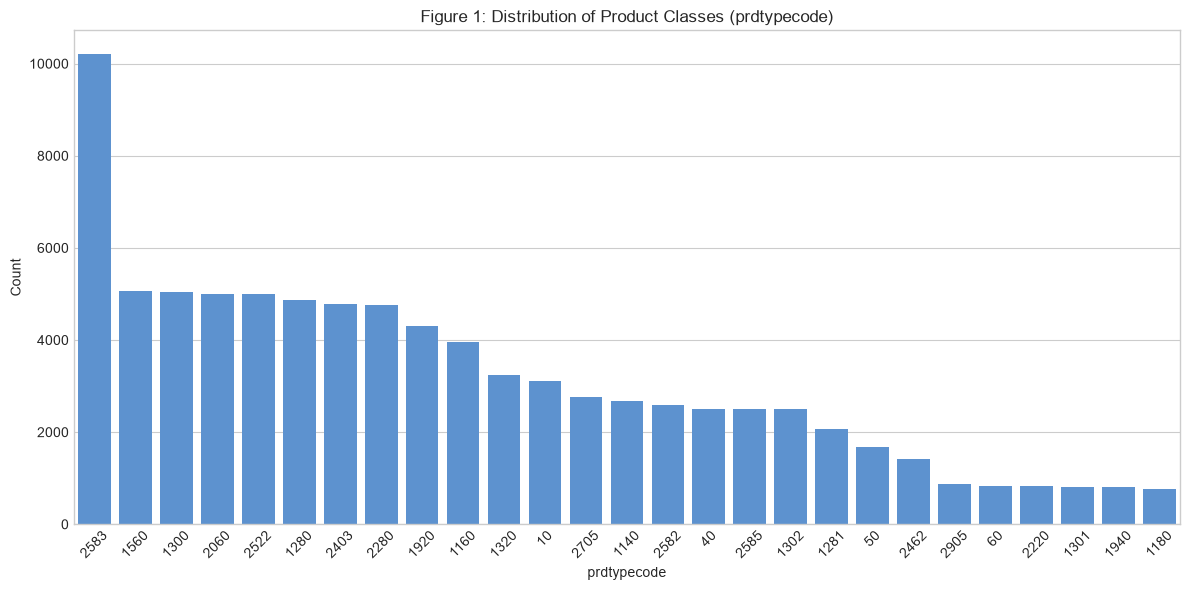

In [ ]:

class_counts = df['prdtypecode'].value_counts()
#print(class_counts)

plt.figure(figsize=(12, 6))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values, color='#4A90E2')
plt.title("Figure 1: Distribution of Product Classes (prdtypecode)")
plt.xlabel("prdtypecode")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 4. Figure 2: Missing Description Rate by Class

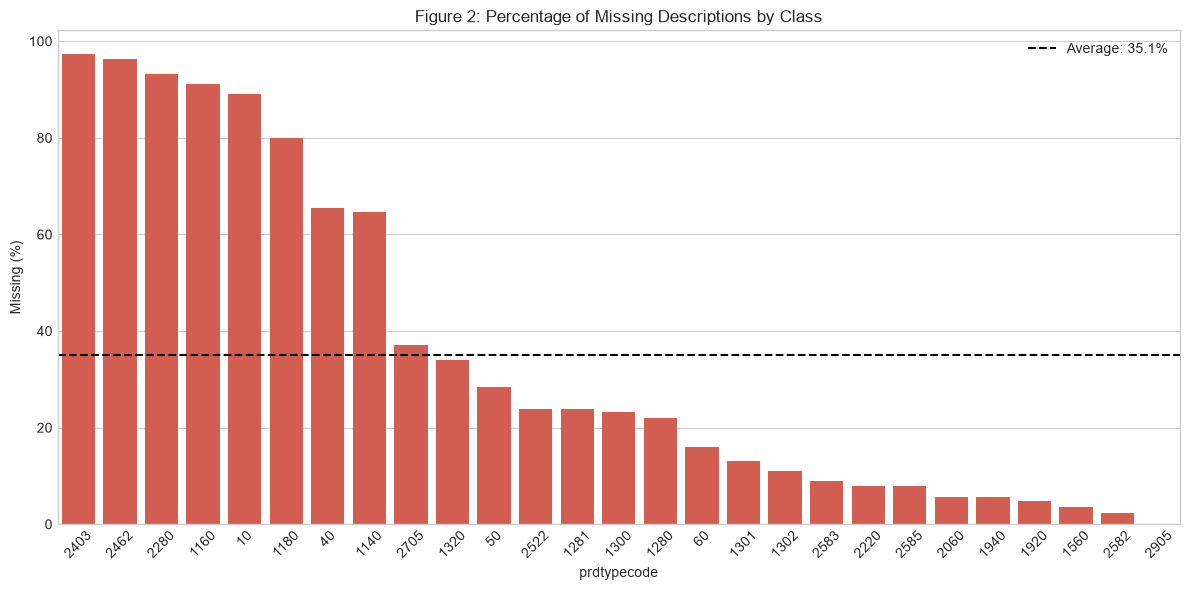

In [5]:
df['missing_desc'] = df['description'].isnull()
missing_by_class = (df.groupby('prdtypecode')['missing_desc'].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=missing_by_class.index.astype(str), y=missing_by_class.values, color='#E74C3C')
plt.axhline(df['missing_desc'].mean() * 100, color='black', linestyle='--', label=f"Average: {df['missing_desc'].mean()*100:.1f}%")
plt.title("Figure 2: Percentage of Missing Descriptions by Class")
plt.xlabel("prdtypecode")
plt.ylabel("Missing (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


## 5. Statistical Test: Chi-Squared Test

In [6]:
table = pd.crosstab(df['prdtypecode'], df['missing_desc'])
chi2, p_val, dof, _ = stats.chi2_contingency(table)
print(f"Chi-square: {chi2:.2f}, p-value: {p_val:.2e}")


Chi-square: 43757.77, p-value: 0.00e+00


## 6. Figure 3 & 4: Text Length Distributions

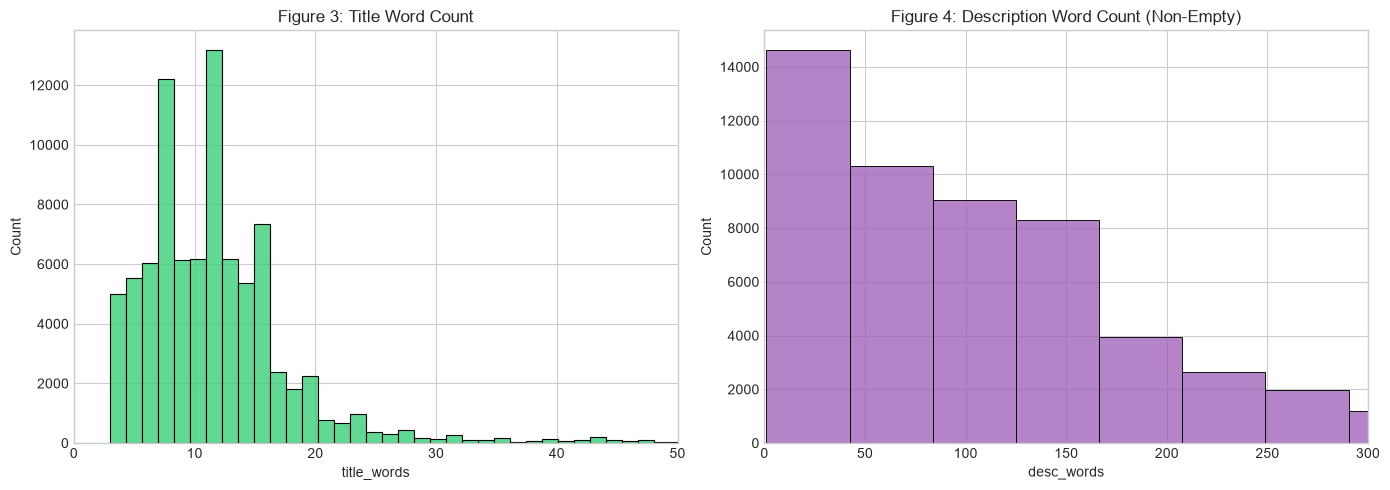

In [7]:
df['title_words'] = df['designation'].fillna('').apply(lambda s: len(str(s).split()))
df['desc_words'] = df['description'].fillna('').apply(lambda s: len(str(s).split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['title_words'], bins=40, color='#2ECC71', ax=axes[0])
axes[0].set_title("Figure 3: Title Word Count")
axes[0].set_xlim(0, 50)

desc_non_null = df[df['desc_words'] > 0]['desc_words']
sns.histplot(desc_non_null, bins=50, color='#9B59B6', ax=axes[1])
axes[1].set_title("Figure 4: Description Word Count (Non-Empty)")
axes[1].set_xlim(0, 300)

plt.tight_layout()
plt.show()


## 7. Figure 5: Sample Images

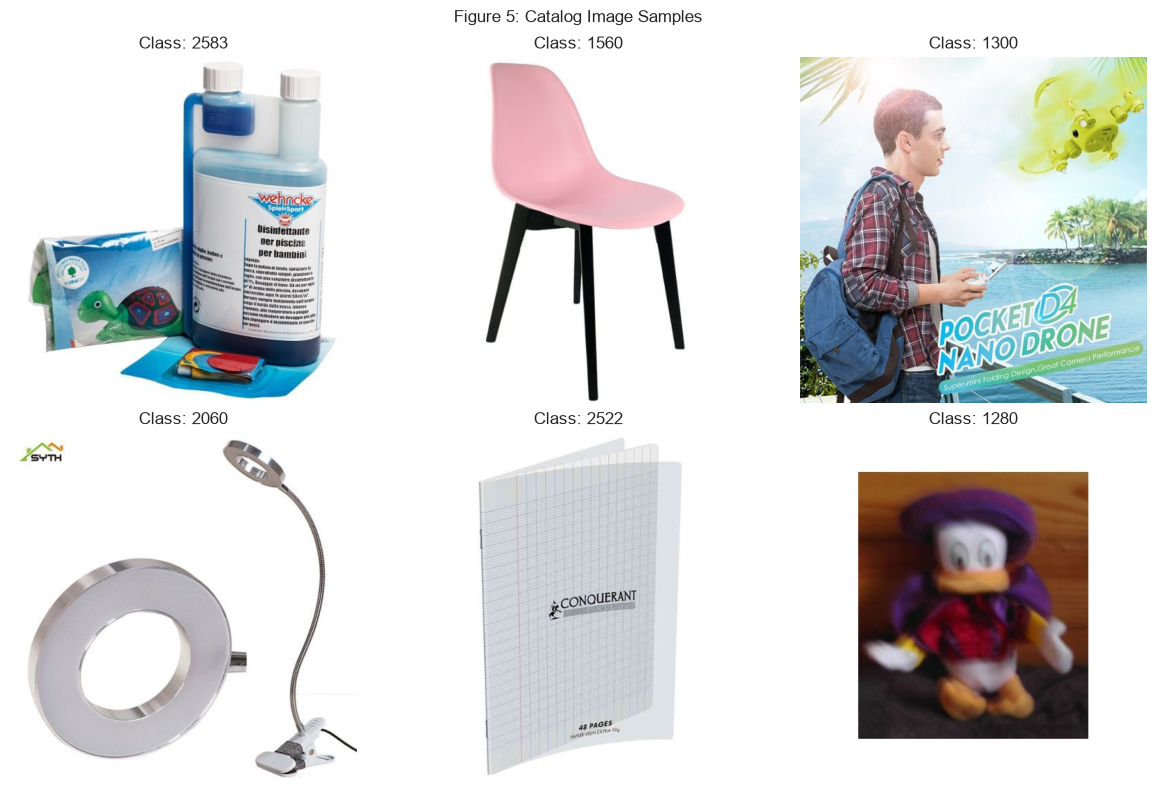

In [8]:
classes = df['prdtypecode'].value_counts().index[:6]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for i, cls in enumerate(classes):
    sample = df[df['prdtypecode'] == cls].iloc[0]
    img_path = get_image_path(sample['imageid'], sample['productid'])
    if os.path.exists(img_path):
        axes[i].imshow(Image.open(img_path))
    axes[i].set_title(f"Class: {cls}")
    axes[i].axis('off')

plt.suptitle("Figure 5: Catalog Image Samples")
plt.tight_layout()
plt.show()


## 8. Figure 6: Manifold Learning (Isomap)

We use Isomap to identify variance factors in the images. Manifold learning allows us to identify variance factors and may eventually help us create new features that are more informative than the raw features in the dataset.

In [ ]:
from sklearn.manifold import Isomap
from src.vision_utils import plot_components

# Sample images and prepare data (using 64x64 to preserve square aspect ratio)
sample = df.sample(100, random_state=42)
img_gray = []
img_rgb = []
for _, row in sample.iterrows():
    path = get_image_path(row["imageid"], row["productid"])
    img = Image.open(path).resize((64, 64))
    img_gray.append(np.array(img.convert("L")))
    img_rgb.append(np.array(img.convert("RGB")))

# Flatten grayscale images for Isomap
data = np.array(img_gray).reshape(len(img_gray), -1)

# Plot components
fig, ax = plt.subplots(figsize=(10, 10))

plot_components(data,
                model=Isomap(n_components=2),
                images=np.array(img_rgb),
                thumb_frac=0.08)

plt.title("Isomap Manifold Projection (Raw Pixels)")
plt.show()
